# Breast cancer

Inspect the Wisconsin Diagnostic Breast Cancer dataset that ships with scikit-learn (`load_breast_cancer`). Each row is one breast mass, imaged with a fine needle aspirate. The 30 features describe the cell nuclei in the image: the mean, the standard error, and the worst value of ten measurements such as radius, texture, and concavity. The target says whether the mass is malignant or benign.

A logistic regression is the baseline. Later experiments change one thing at a time.

## Load the dataset

In [1]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)

df = data.data.copy()
df["target"] = data.target

print(df.shape)
print(list(df.columns))
print(data.target_names)

(569, 31)
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']
['malignant' 'benign']


## Inspect the data

`df` is 569 rows: the 30 numeric features plus `target`. Every column is a float except `target`, and no column has missing values.

In [2]:
print(df.head())
df.info()
print(df.describe())
print(df.isnull().sum().sum())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

## Investigate the target

`target` is 0 for malignant (212 masses, 37%) and 1 for benign (357 masses, 63%). The classes are moderately imbalanced, so the split later will be stratified.

In [3]:
print(df["target"].value_counts().sort_index())
print(df["target"].map(dict(enumerate(data.target_names))).value_counts(normalize=True))

target
0    212
1    357
Name: count, dtype: int64
target
benign       0.627417
malignant    0.372583
Name: proportion, dtype: float64


## Visualise relationships

The pairplot crosses mean radius, mean texture, mean smoothness, and mean concavity, colored by diagnosis. Malignant masses sit toward larger radius and higher concavity, and the two classes separate cleanly on those axes. Texture and smoothness overlap more.

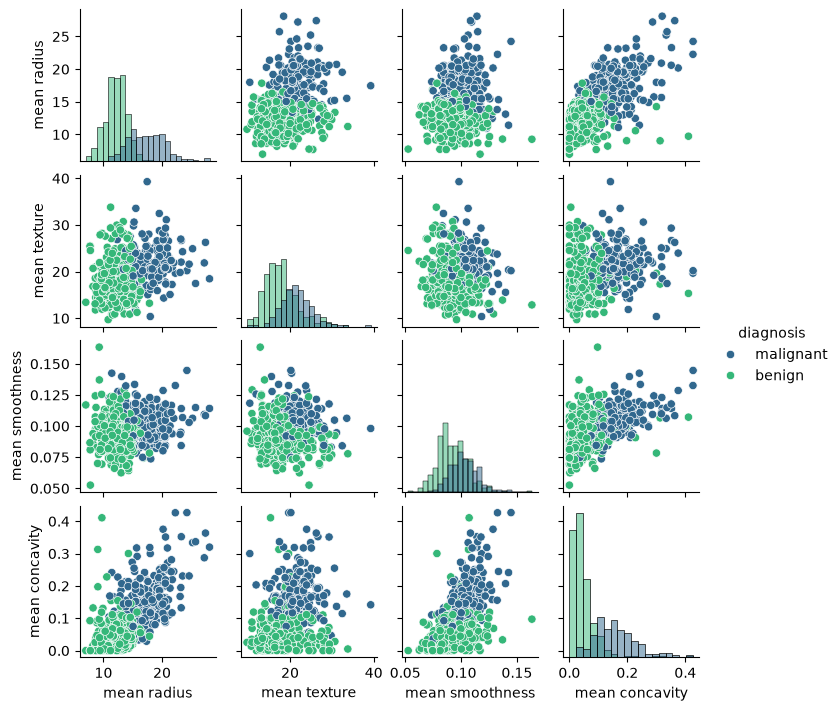

In [4]:
%matplotlib inline

import matplotlib.pyplot as plt
import seaborn as sns

plot_df = df[["mean radius", "mean texture", "mean smoothness", "mean concavity", "target"]].copy()
plot_df["diagnosis"] = plot_df.pop("target").map(dict(enumerate(data.target_names)))

sns.pairplot(plot_df, hue="diagnosis", diag_kind="hist", height=1.8, palette="viridis")
plt.show()

## Train and test split

Hold out 20% of the masses and stratify on `target`, so malignant and benign keep the same share in both sets.

The split gives 455 training rows and 114 test rows. Malignant is 37.4% of the training set and 36.8% of the test set, so the proportions held.

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).sort_index())
print(y_test.value_counts(normalize=True).sort_index())

(455, 30) (114, 30)
target
0    0.373626
1    0.626374
Name: proportion, dtype: float64
target
0    0.368421
1    0.631579
Name: proportion, dtype: float64


## Baseline

A logistic regression inside a pipeline with a standard scaler. The features sit on very different scales (`mean area` is in the hundreds, `mean smoothness` is below 1), so scaling comes first. The score is accuracy on the held-out rows.

The baseline scores 0.982 on the 114 held-out masses: 112 correct, 2 wrong. One malignant mass was predicted benign and one benign mass was predicted malignant. Precision and recall are 0.98 for malignant and 0.99 for benign.

With only 114 test rows, one mistake moves accuracy by about 0.9 points, so differences between models this close will be hard to read from a single split. A malignant mass called benign is the costlier error, which is why recall on the malignant row matters most.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000))
baseline.fit(X_train, y_train)

pred = baseline.predict(X_test)
print("accuracy:", accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, target_names=data.target_names))

accuracy: 0.9824561403508771
[[41  1]
 [ 1 71]]
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## Conclusion

The table has 569 breast masses and 30 numeric features, with no missing values. 212 are malignant and 357 are benign. The stratified 80/20 split gave 455 training rows and 114 test rows.

A scaled logistic regression scored 0.982 accuracy on the 114 held-out rows, with 2 errors: one malignant mass called benign and one benign mass called malignant. Precision and recall are 0.98 for malignant and 0.99 for benign.

The baseline is already close to the ceiling on this split. The two classes separate cleanly on the size and concavity features, and one more correct row would only move accuracy by 0.9 points, so there is nothing a further experiment could show reliably. The study stops at the baseline.